# Week 3 - Tuesday: Hierarchical Clustering + PCA Visualisation
Dataset: `Mall_Customers.csv` (same file as Monday).

Plan for today:
1. Dendrogram on Income and Spending Score, and decide where to cut
2. `AgglomerativeClustering` vs K-Means (same k): do they agree?
3. Cluster on more features (Age, Income, Spending, Gender) and visualise with PCA
4. Profile the clusters and give each a plain-English name

## 1. Imports and data

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

df = pd.read_csv("Mall_Customers.csv")
# Some copies call this column Gender, some Genre. Use one name from here on.
df = df.rename(columns={"Gender": "Genre"})
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 2. Scale the two main features
Same as Monday: Annual Income and Spending Score, standardised.

In [32]:
features2 = ["Annual Income (k$)", "Spending Score (1-100)"]
X2 = StandardScaler().fit_transform(df[features2])
X2.shape

(200, 2)

## 3. Dendrogram
Hierarchical (agglomerative) clustering starts with every point as its own cluster and repeatedly merges the two closest clusters. The result is a tree, the **dendrogram**.

`linkage="ward"` merges the pair of clusters that increases the total within-cluster variance the least. It tends to give compact, similar-sized clusters, so it is the usual first choice.

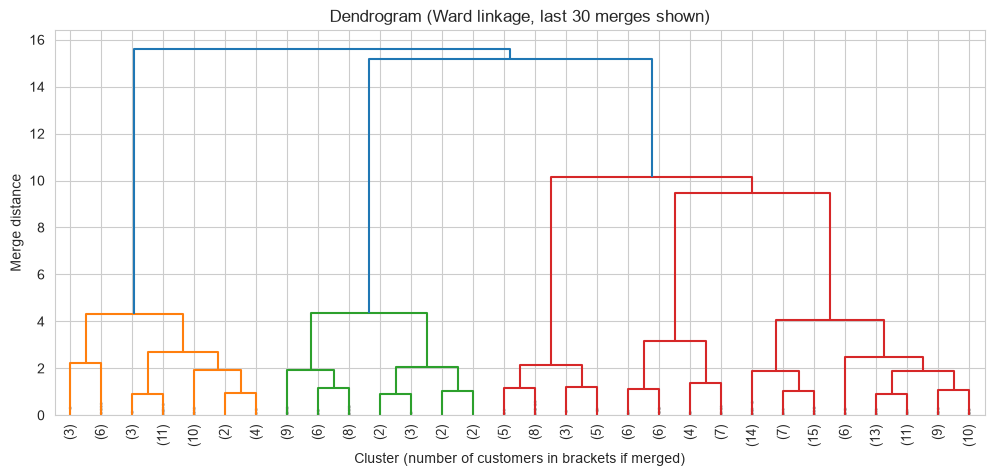

In [33]:
Z = linkage(X2, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True)
plt.title("Dendrogram (Ward linkage, last 30 merges shown)")
plt.xlabel("Cluster (number of customers in brackets if merged)")
plt.ylabel("Merge distance")
plt.show()

**How to cut the dendrogram:** draw a horizontal line across the tallest vertical gaps where no merging happens. The number of vertical lines the cut crosses is the number of clusters.

Below, a cut at a chosen height is drawn on the full dendrogram. Change `CUT_HEIGHT` and see how many clusters you get.

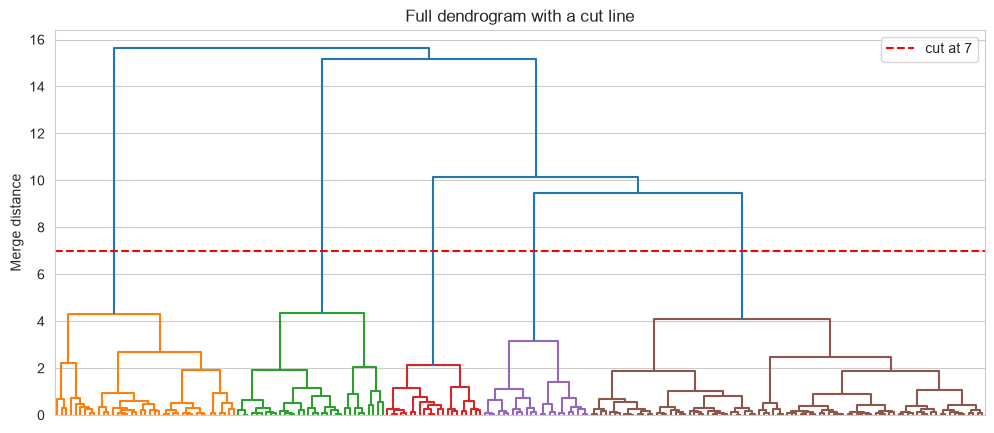

Clusters at this cut: 5


In [34]:
CUT_HEIGHT = 7   # try 5, 7, 10, 15 and watch the cluster count change

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True, color_threshold=CUT_HEIGHT)
plt.axhline(CUT_HEIGHT, color="red", linestyle="--", label=f"cut at {CUT_HEIGHT}")
plt.title("Full dendrogram with a cut line")
plt.ylabel("Merge distance")
plt.legend()
plt.show()

n_clusters_cut = len(np.unique(fcluster(Z, t=CUT_HEIGHT, criterion="distance")))
print("Clusters at this cut:", n_clusters_cut)

In [35]:
# Which cut heights give which number of clusters? The last merge distances show the big gaps.
print("Last 10 merge distances (largest at the bottom):")
print(np.round(Z[-10:, 2], 2))

Last 10 merge distances (largest at the bottom):
[ 2.49  2.7   3.15  4.07  4.31  4.35  9.45 10.14 15.19 15.62]


A big jump between two consecutive merge distances means the algorithm had to join two clusters that are far apart. Cutting just before that jump is a natural choice.

## 4. Agglomerative vs K-Means (same k)

In [36]:
K = 5

agg = AgglomerativeClustering(n_clusters=K, linkage="ward")
agg_labels = agg.fit_predict(X2)

km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
km_labels = km.fit_predict(X2)

print("Silhouette  Agglomerative:", round(silhouette_score(X2, agg_labels), 4))
print("Silhouette  K-Means      :", round(silhouette_score(X2, km_labels), 4))
print("Adjusted Rand Index (1.0 = identical groupings):",
      round(adjusted_rand_score(km_labels, agg_labels), 4))

Silhouette  Agglomerative: 0.5538
Silhouette  K-Means      : 0.5547
Adjusted Rand Index (1.0 = identical groupings): 0.942


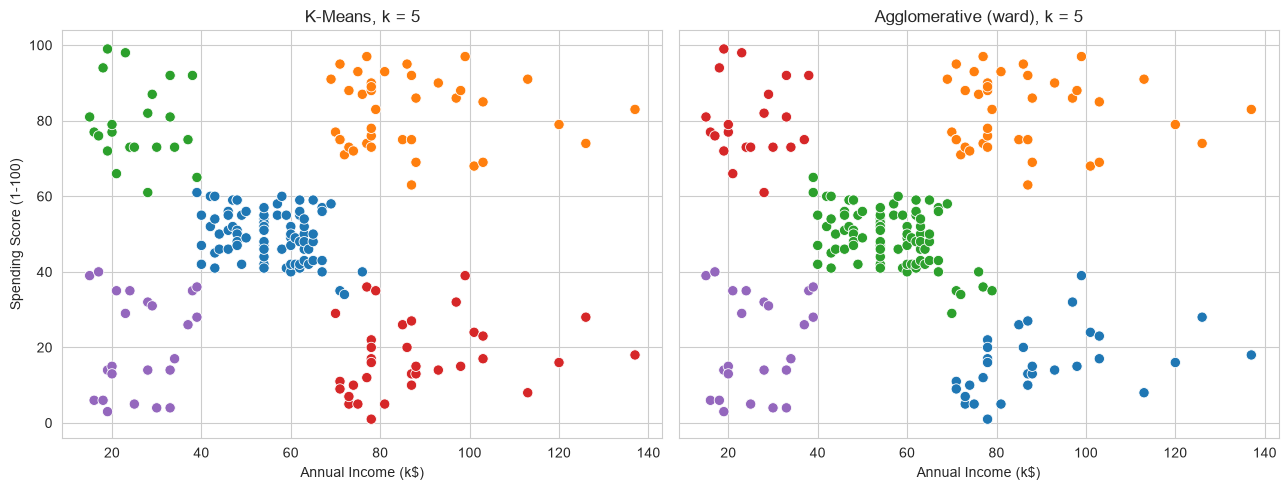

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, labels, title in zip(axes, [km_labels, agg_labels], ["K-Means", "Agglomerative (ward)"]):
    sns.scatterplot(x=df[features2[0]], y=df[features2[1]], hue=labels,
                    palette="tab10", s=55, ax=ax, legend=False)
    ax.set_title(f"{title}, k = {K}")
plt.tight_layout(); plt.show()

In [38]:
# Cross-tab: how do the two sets of labels line up? (cluster numbers are arbitrary, look for one big number per row)
pd.crosstab(pd.Series(km_labels, name="K-Means"), pd.Series(agg_labels, name="Agglomerative"))

Agglomerative,0,1,2,3,4
K-Means,,,,,
0,0,0,81,0,0
1,0,39,0,0,0
2,0,0,1,21,0
3,32,0,3,0,0
4,0,0,0,0,23


**What to look for:** on this kind of well-separated data the two methods usually find almost the same groups. A high Adjusted Rand Index and one dominant number per row in the cross-tab means they agree. Cluster *numbers* are arbitrary, so never compare them directly.

## 5. More features: Age, Income, Spending, Gender
With 4 features we cannot plot the data directly. We cluster in 4-D, then use **PCA** to squash it to 2-D just for the picture.

 k  silhouette
 2       0.252
 3       0.260
 4       0.298
 5       0.304
 6       0.331
 7       0.357
 8       0.388
 9       0.403
10       0.421


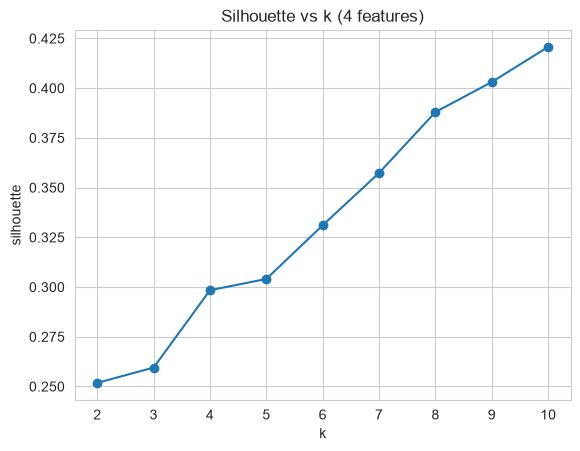

In [39]:
df_enc = df.copy()
df_enc["Genre_enc"] = (df_enc["Genre"] == "Female").astype(int)   # Female = 1, Male = 0

features4 = ["Age", "Annual Income (k$)", "Spending Score (1-100)", "Genre_enc"]
X4 = StandardScaler().fit_transform(df_enc[features4])

# Choose k for the 4-feature version
rows = []
for k in range(2, 11):
    lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X4)
    rows.append((k, silhouette_score(X4, lab)))
res4 = pd.DataFrame(rows, columns=["k", "silhouette"])
print(res4.round(3).to_string(index=False))

plt.plot(res4["k"], res4["silhouette"], "o-")
plt.title("Silhouette vs k (4 features)")
plt.xlabel("k"); plt.ylabel("silhouette"); plt.show()

Pick `K4` yourself. Silhouette scores are much lower here than with 2 features (about 0.25 to 0.42, against 0.55 before). In a test run the score kept rising up to k = 10 with no clear peak, so the silhouette alone does not give a clean answer. In that case choose k by whether the clusters are **interpretable**, and say so in your notes. k = 6 is used below as a reasonable starting point.

In [40]:
K4 = 6   # change after looking at the plot above

km4 = KMeans(n_clusters=K4, n_init=10, random_state=RANDOM_STATE)
df_enc["Cluster4"] = km4.fit_predict(X4)
print("Silhouette (k =", K4, "):", round(silhouette_score(X4, df_enc["Cluster4"]), 4))
print(df_enc["Cluster4"].value_counts().sort_index())

Silhouette (k = 6 ): 0.3311
Cluster4
0    41
1    38
2    34
3    35
4    23
5    29
Name: count, dtype: int64


## 6. PCA to 2-D

Variance explained per component: [0.337 0.262]
Total variance kept by 2 components: 59.9 %


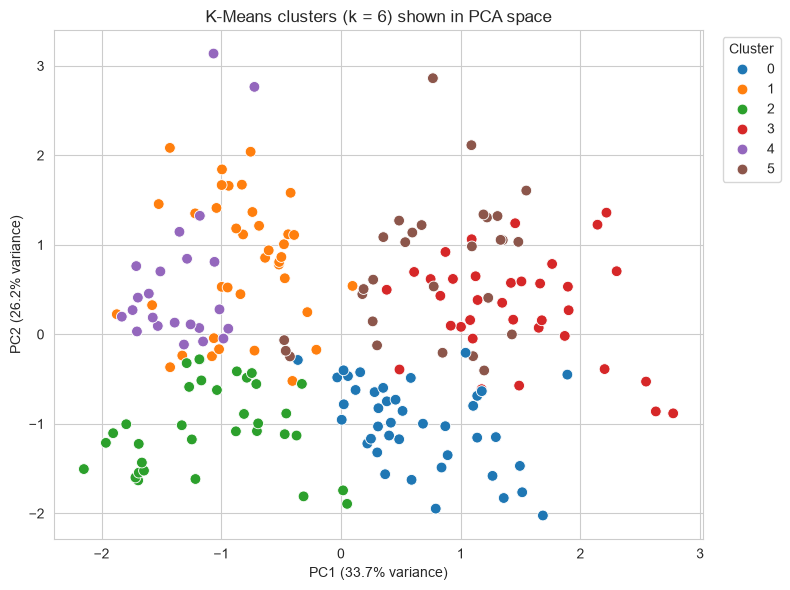

In [41]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X4_pca = pca.fit_transform(X4)

print("Variance explained per component:", pca.explained_variance_ratio_.round(3))
print("Total variance kept by 2 components:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X4_pca[:, 0], y=X4_pca[:, 1], hue=df_enc["Cluster4"],
                palette="tab10", s=60)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title(f"K-Means clusters (k = {K4}) shown in PCA space")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [42]:
# What do the two components mean? Look at how much each original feature contributes.
loadings = pd.DataFrame(pca.components_.T, index=features4, columns=["PC1", "PC2"])
loadings.round(2)

,PC1,PC2
Age,0.69,-0.10
Annual Income (k$),-0.01,0.77
Spending Score (1-100),-0.69,0.10
Genre_enc,-0.23,-0.63


**Look at `pct_female` in the profile table above.** Gender is a 0/1 column, and after scaling it separates points very strongly, so several clusters end up being almost all-female or all-male. That is a sign that Gender is driving the split more than behaviour is. Compare with the 2-feature clustering from Monday and write down which one is more useful for a business.

**Reading the PCA plot:** if the 2 components keep most of the variance, the picture is a fair summary of the 4-D clusters. If they keep much less, clusters that look overlapping in 2-D may still be well separated in the full space. PCA is only for the picture here, the clustering itself was done on all 4 features.

## 7. Profile the clusters

In [43]:
profile = df_enc.groupby("Cluster4").agg(
    customers=("CustomerID", "count"),
    avg_age=("Age", "mean"),
    avg_income=("Annual Income (k$)", "mean"),
    avg_spending=("Spending Score (1-100)", "mean"),
    pct_female=("Genre_enc", lambda s: s.mean() * 100),
).round(1)
profile

,customers,avg_age,avg_income,avg_spending,pct_female
Cluster4,,,,,
0,41,50.6,49.7,40.1,100.0
1,38,28.1,58.3,71.3,0.0
2,34,26.0,39.5,59.5,100.0
3,35,55.6,52.8,36.2,0.0
4,23,32.1,90.0,81.4,91.3
5,29,36.5,89.5,18.0,55.2


In [44]:
def suggest_name(r):
    inc = "high income" if r["avg_income"] >= 60 else ("low income" if r["avg_income"] < 40 else "mid income")
    sp  = "high spending" if r["avg_spending"] >= 60 else ("low spending" if r["avg_spending"] < 40 else "mid spending")
    age = "younger" if r["avg_age"] < 35 else ("older" if r["avg_age"] >= 45 else "middle-aged")
    return f"{age}, {inc}, {sp}"

profile["suggested_name"] = profile.apply(suggest_name, axis=1)
profile

,customers,avg_age,avg_income,avg_spending,pct_female,suggested_name
Cluster4,,,,,,
0,41,50.6,49.7,40.1,100.0,"older, mid income, mid spending"
1,38,28.1,58.3,71.3,0.0,"younger, mid income, high spending"
2,34,26.0,39.5,59.5,100.0,"younger, low income, mid spending"
3,35,55.6,52.8,36.2,0.0,"older, mid income, low spending"
4,23,32.1,90.0,81.4,91.3,"younger, high income, high spending"
5,29,36.5,89.5,18.0,55.2,"middle-aged, high income, low spending"


These names come from simple thresholds, so rename them in your own words. For each cluster also write one line on **what a business might do** with it, for example: *high income, high spending: loyalty offers and premium products*.

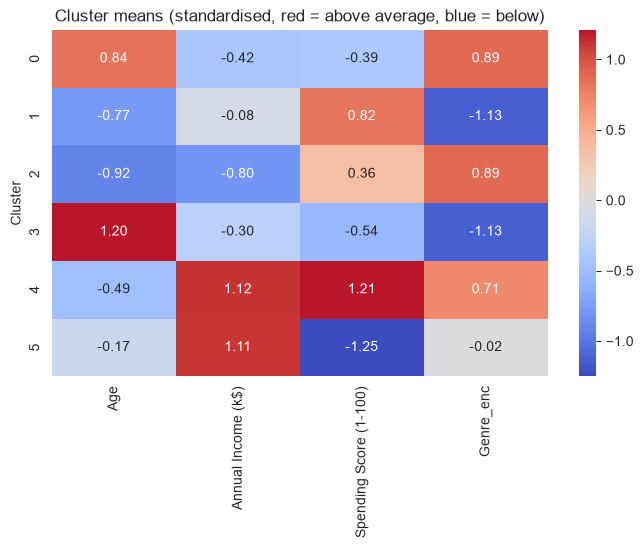

In [45]:
# Same profile as a picture: mean of each feature per cluster (standardised so they share one scale)
prof_z = pd.DataFrame(X4, columns=features4).groupby(df_enc["Cluster4"].values).mean()
plt.figure(figsize=(8, 4.5))
sns.heatmap(prof_z, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cluster means (standardised, red = above average, blue = below)")
plt.ylabel("Cluster"); plt.show()